In [1]:
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True, scaled=False)
diabetes.data

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.00,157.0,93.2,38.0,4.00,4.8598,87.0
1,48.0,1.0,21.6,87.00,183.0,103.2,70.0,3.00,3.8918,69.0
2,72.0,2.0,30.5,93.00,156.0,93.6,41.0,4.00,4.6728,85.0
3,24.0,1.0,25.3,84.00,198.0,131.4,40.0,5.00,4.8903,89.0
4,50.0,1.0,23.0,101.00,192.0,125.4,52.0,4.00,4.2905,80.0
...,...,...,...,...,...,...,...,...,...,...
437,60.0,2.0,28.2,112.00,185.0,113.8,42.0,4.00,4.9836,93.0
438,47.0,2.0,24.9,75.00,225.0,166.0,42.0,5.00,4.4427,102.0
439,60.0,2.0,24.9,99.67,162.0,106.6,43.0,3.77,4.1271,95.0
440,36.0,1.0,30.0,95.00,201.0,125.2,42.0,4.79,5.1299,85.0


In [2]:
diabetes.target

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [3]:
X=diabetes.data
y=diabetes.target
df=X.join(y)
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.00,157.0,93.2,38.0,4.00,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.00,183.0,103.2,70.0,3.00,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.00,156.0,93.6,41.0,4.00,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.00,198.0,131.4,40.0,5.00,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.00,192.0,125.4,52.0,4.00,4.2905,80.0,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,60.0,2.0,28.2,112.00,185.0,113.8,42.0,4.00,4.9836,93.0,178.0
438,47.0,2.0,24.9,75.00,225.0,166.0,42.0,5.00,4.4427,102.0,104.0
439,60.0,2.0,24.9,99.67,162.0,106.6,43.0,3.77,4.1271,95.0,132.0
440,36.0,1.0,30.0,95.00,201.0,125.2,42.0,4.79,5.1299,85.0,220.0


In [4]:
df.isna().sum() #No missing values

,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


<Axes: >

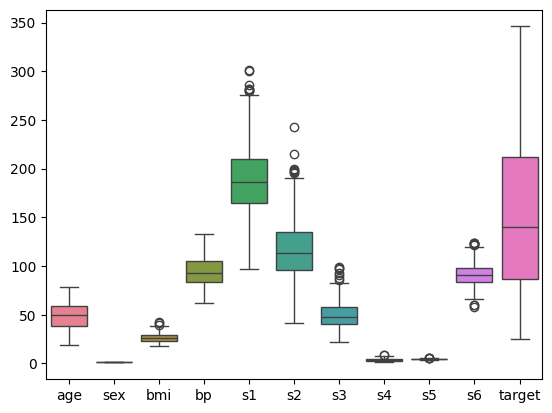

In [5]:
import seaborn as sns #No need to handle outliers

sns.boxplot(df)

In [6]:
#Since all values  are numericl no need of encoding
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

scaler=StandardScaler()
Xtrain=scaler.fit_transform(X_train)
Xtest=scaler.transform(X_test)

In [7]:
Xtrain.shape


(353, 10)

In [8]:
Xtest.shape

(89, 10)

NameError: name 'plt' is not defined

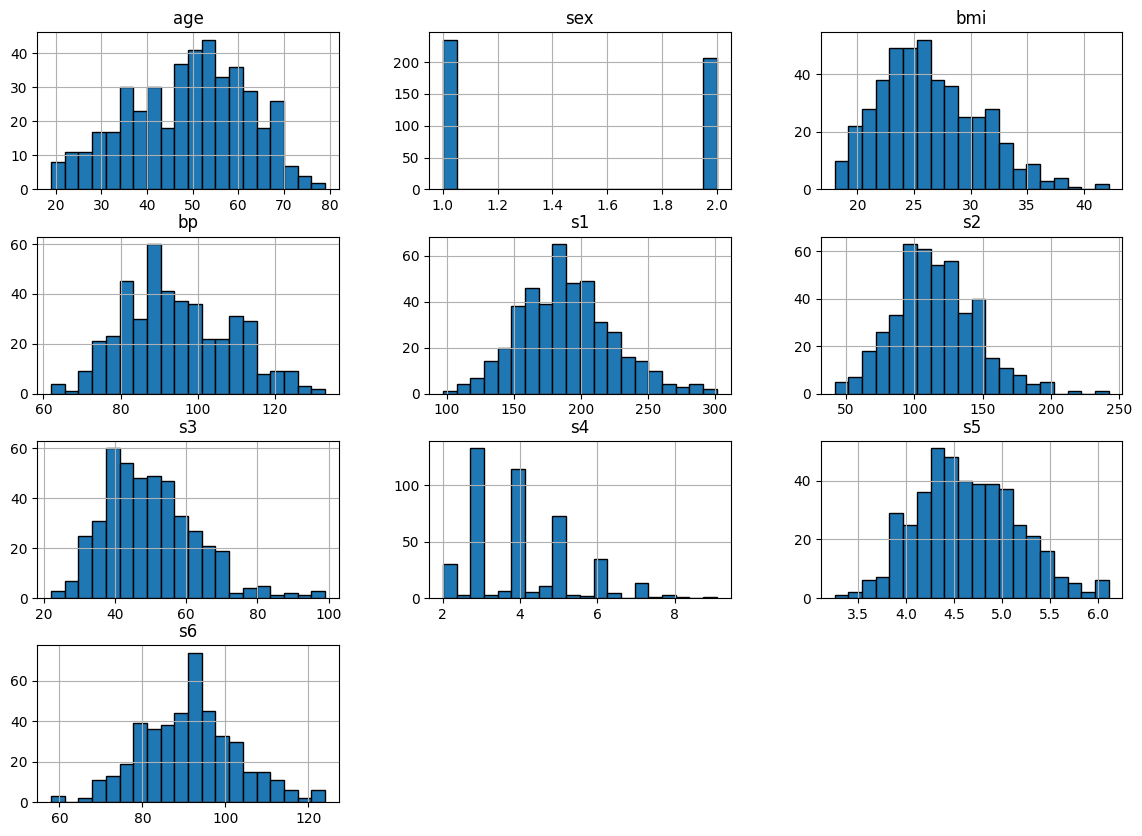

In [10]:
X.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Diabetes Dataset Features")
plt.tight_layout()
plt.show()

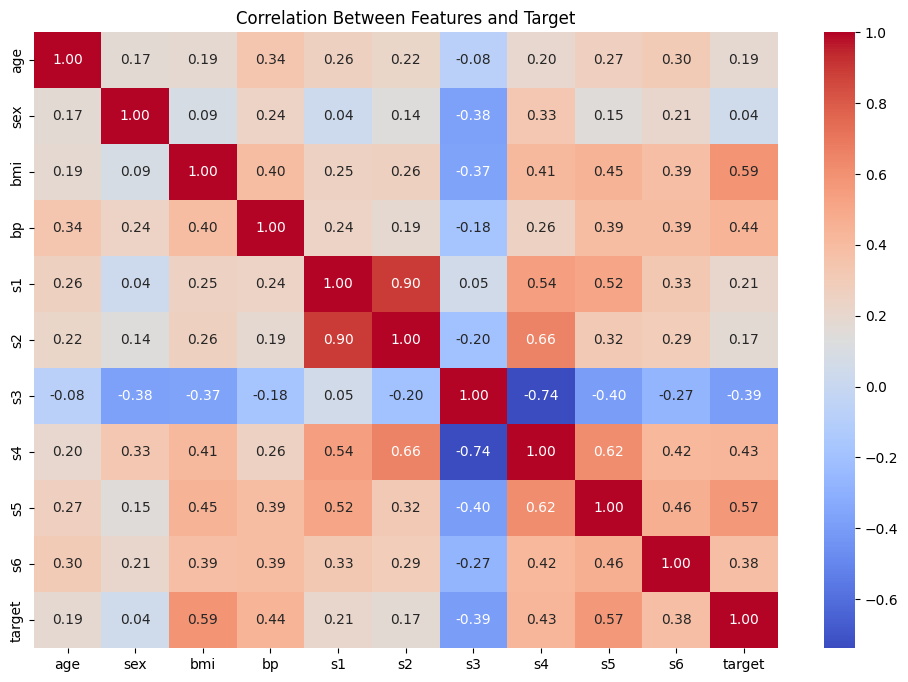

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Features and Target")
plt.show()

In [12]:
# Calculate skewness of all independent variables
skewness = X.skew()

print(skewness) #data is not heavilly right skewed or left skewed

age   -0.231382
sex    0.127385
bmi    0.598148
bp     0.290658
s1     0.378108
s2     0.436592
s3     0.799255
s4     0.735374
s5     0.291754
s6     0.207917
dtype: float64


In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

model=keras.Sequential([
    keras.Input(shape=(10,)),
    layers.Dense(16,activation='relu'),
    layers.Dense(8,activation='relu'),
    layers.Dense(1,activation='linear') #since its not  a multiclass classification problem
                 ])


In [14]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
early_stopping=keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=100,
    restore_best_weights=True
)

In [17]:
model_trained=model.fit(Xtrain,y_train,epochs=300,batch_size=16,validation_split=0.2,callbacks=[early_stopping])
print("Training completed.")

Epoch 1/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - loss: 31560.9297 - mae: 158.7721 - val_loss: 22459.3848 - val_mae: 133.9727
Epoch 2/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31473.3574 - mae: 158.4869 - val_loss: 22395.0957 - val_mae: 133.7240
Epoch 3/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 31395.1270 - mae: 158.2291 - val_loss: 22331.8008 - val_mae: 133.4825
Epoch 4/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 31314.6523 - mae: 157.9685 - val_loss: 22265.0273 - val_mae: 133.2300
Epoch 5/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31224.5078 - mae: 157.6839 - val_loss: 22189.7168 - val_mae: 132.9494
Epoch 6/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31114.6562 - mae: 157.3459 - val_loss: 22100.5234 - val_mae: 132.6225
Epoch 7/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30970.5605 - mae: 156.9165 - val_loss: 21982.6934 - val_mae: 132.2042
Epoch 8/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30780.5176 - mae: 156.3643 - val_loss

In [18]:
y_pred = model.predict(Xtest).flatten()

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step


In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("----------------")
print("Mean Squared Error:", round(mse, 2))
print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation
----------------
Mean Squared Error: 2847.1
Mean Absolute Error: 42.08
R2 Score: 0.4626


In [ ]:
#compared to the lyers with 64,32,1 as hidden layer inputs the current 16,8,1 gives better performance .
#currently the best R2 score obtained is 0.4626